Reading the json file with spark dataframes

In [1]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("CensusAnalysis").getOrCreate()

df = spark.read.json("census_2010.json")
df.show(10)

+---+-------+-------+-------+----+
|age|females|  males|  total|year|
+---+-------+-------+-------+----+
|  0|1994141|2085528|4079669|2010|
|  1|1997991|2087350|4085341|2010|
|  2|2000746|2088549|4089295|2010|
|  3|2002756|2089465|4092221|2010|
|  4|2004366|2090436|4094802|2010|
|  5|2005925|2091803|4097728|2010|
|  6|2007781|2093905|4101686|2010|
|  7|2010281|2097080|4107361|2010|
|  8|2013771|2101670|4115441|2010|
|  9|2018603|2108014|4126617|2010|
+---+-------+-------+-------+----+
only showing top 10 rows



Discovering the data types and column names of it

In [3]:
df.printSchema()
column_names = df.columns
column_types = df.dtypes
print(column_names, column_types, sep="\n")

root
 |-- age: long (nullable = true)
 |-- females: long (nullable = true)
 |-- males: long (nullable = true)
 |-- total: long (nullable = true)
 |-- year: long (nullable = true)

['age', 'females', 'males', 'total', 'year']
[('age', 'bigint'), ('females', 'bigint'), ('males', 'bigint'), ('total', 'bigint'), ('year', 'bigint')]


Accessing 'age' column in various ways and displaying 10 records from it

In [4]:
age_dot = df.age
age_bracket = df["age"]
age_select = df.select("age")   

age_select.show(10)

+---+
|age|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
|  5|
|  6|
|  7|
|  8|
|  9|
+---+
only showing top 10 rows



Creating new column using withColumn method

In [6]:
from pyspark.sql.functions import col
df_with_ratio = df.withColumn("female_male_ratio", col("females")/col("males"))
ratio_preview = df_with_ratio.select("age","females","males","female_male_ratio")

ratio_preview.show(10)

+---+-------+-------+------------------+
|age|females|  males| female_male_ratio|
+---+-------+-------+------------------+
|  0|1994141|2085528|0.9561804013180355|
|  1|1997991|2087350|0.9571902172611205|
|  2|2000746|2088549|0.9579598084603234|
|  3|2002756|2089465|0.9585018174508786|
|  4|2004366|2090436|0.9588267710659403|
|  5|2005925|2091803|0.9589454647497876|
|  6|2007781|2093905|0.9588691941611487|
|  7|2010281|2097080|0.9586095904781887|
|  8|2013771|2101670| 0.958176592899932|
|  9|2018603|2108014|0.9575851963032503|
+---+-------+-------+------------------+
only showing top 10 rows



In [7]:
female_majority_df = df_with_ratio.filter(col("female_male_ratio") > 1.0)

female_majority_preview = female_majority_df.select("age", "females", "males","female_male_ratio")

female_majority_preview.show(10)

+---+-------+-------+------------------+
|age|females|  males| female_male_ratio|
+---+-------+-------+------------------+
| 34|2025969|2020204|1.0028536722034012|
| 35|2029981|2018080| 1.005897189407754|
| 36|2036269|2018137| 1.008984523845507|
| 37|2045241|2022787|1.0111005261552501|
| 38|2056401|2032469|1.0117748413382934|
| 39|2070132|2046398| 1.011597939403772|
| 40|2085229|2061474|1.0115233080795587|
| 41|2099423|2076069|1.0112491444166836|
| 42|2123189|2098014|1.0119994432830286|
| 43|2160806|2130169| 1.014382426934201|
+---+-------+-------+------------------+
only showing top 10 rows



Aggregating the totals using sum() and groupBy() methods

In [9]:

from pyspark.sql.functions import col, avg, when, sum
df_with_ratio = df.withColumn("female_male_ratio", col("females") / col("males"))
df_categorized = df_with_ratio.withColumn(
                "age_group",
            when(col("age") < 18, "Minor")
            .when((col("age") >=18) & (col("age") <= 64) , "Working Age")
            .otherwise("Retirement Age")
)

age_group_totals = df_categorized.groupBy("age_group").agg(sum("total").alias("group_population"))

age_group_totals.show()

+--------------+----------------+
|     age_group|group_population|
+--------------+----------------+
|   Working Age|       196296661|
|         Minor|        75156171|
|Retirement Age|        40794284|
+--------------+----------------+



Chaining Operations to perform analysis

In [10]:
df_with_ratio = df.withColumn("female_male_ratio", col("females") / col("males"))
youth_analysis = (df_with_ratio
                .withColumn("gender_gap", col("females") - col("males"))
                .filter(col("age")<18)
                .select("age","total","gender_gap","female_male_ratio")
                .orderBy("age")  
)

youth_analysis.show(10)

+---+-------+----------+------------------+
|age|  total|gender_gap| female_male_ratio|
+---+-------+----------+------------------+
|  0|4079669|    -91387|0.9561804013180355|
|  1|4085341|    -89359|0.9571902172611205|
|  2|4089295|    -87803|0.9579598084603234|
|  3|4092221|    -86709|0.9585018174508786|
|  4|4094802|    -86070|0.9588267710659403|
|  5|4097728|    -85878|0.9589454647497876|
|  6|4101686|    -86124|0.9588691941611487|
|  7|4107361|    -86799|0.9586095904781887|
|  8|4115441|    -87899| 0.958176592899932|
|  9|4126617|    -89411|0.9575851963032503|
+---+-------+----------+------------------+
only showing top 10 rows



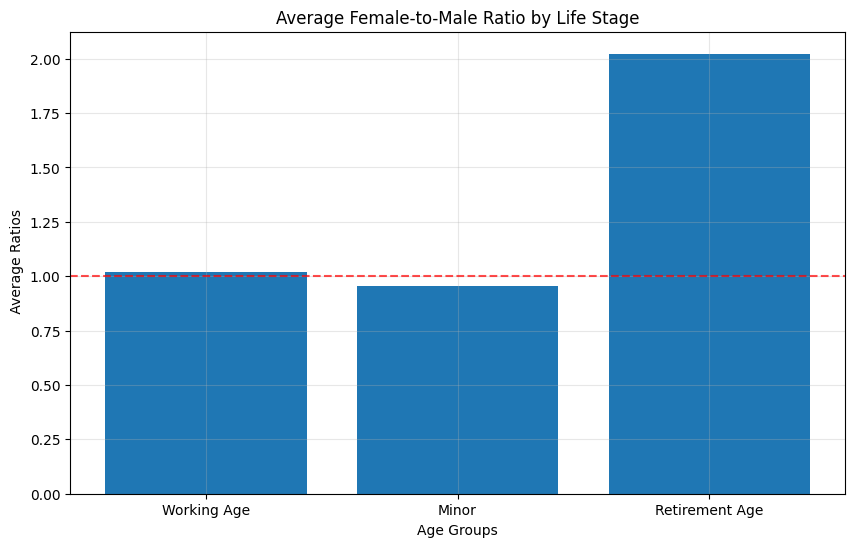

In [13]:
import matplotlib.pyplot as plt
# Create categories and calculate average ratios per category
category_ratios = (df
    .withColumn("female_male_ratio", col("females") / col("males"))
    .withColumn("age_group", 
        when(col("age") < 18, "Minor")
        .when(col("age") < 65, "Working Age")
        .otherwise("Retirement Age"))
    .groupBy("age_group")
    .agg(avg("female_male_ratio").alias("avg_ratio"))
)

category_pandas = category_ratios.toPandas()
plt.figure(figsize=(10, 6))
plt.bar(category_pandas["age_group"],category_pandas['avg_ratio'])
plt.axhline(y=1.0, color='red', linestyle='--', alpha=0.7)
plt.title('Average Female-to-Male Ratio by Life Stage')
plt.xlabel('Age Groups')
plt.ylabel(' Average Ratios')
plt.grid(True, alpha=0.3)
plt.show()